# Visualize Dissociation Rates
### Import libraries

In [1]:
import os
import sys
import importlib
import numpy as np
import pandas as pd
import tensorflow as tf

from tqdm.notebook import tqdm

In [2]:
from utils import add_package_path

Paths

In [3]:
# Current Working Directory
cwd = os.getcwd()
# WORKSPACE
ws = os.environ['WORKSPACE_PATH']

In [4]:
prefix = '/home/zanardi/Workspace/ML/PyCOMET'
paths = {
    # PyCOMET source dir
    'pycomet': prefix + '/pycomet/',
    # SurQCT source dir
    'surqct': prefix + '/pycomet/examples/SurQCT/',
    # PyCOMET input module
    'inputs': prefix + '/run/SurQCT/O3_UMN/tests/Diss/config.08/run.01',
    # SurQCT input module
    'InputData': prefix + '/run/SurQCT/O3_UMN/tests/Diss/datagen/genTrainData/'
}
add_package_path(paths)

In [5]:
# Output directory
out = cwd + '/Output/DissRates/c07/'
if not os.path.exists(out):
    os.makedirs(out)

### Initialize PyCOMET model
Working case

In [6]:
os.chdir(paths['inputs'])

Import additional modules

In [7]:
from pycomet.utilities import utils
from pycomet.apps import functions as fun
# Inputs
import inputs
from inputs.general import flags

Compile model

In [8]:
# Load network architecture
net = fun._net(
    input_mod=inputs
)
# Finalize model
for k in ('train', 'save'):
    flags[k] = 0
flags['load'] = 2
model = fun._model(
    flags=flags,
    input_mod=inputs,
    net=net
)


[PyCOMET]: Initializing 'FFNN' network ...

[PyCOMET]: Building 'FFNN' network ...
Model: "SurQCT_FFNN"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_1 (InputLayer)         [(None, 4)]               0         
_________________________________________________________________
normalization (Normalization (None, 4)                 9         
_________________________________________________________________
ff_block (FFBlock)           (None, 1)                 641       
Total params: 650
Trainable params: 641
Non-trainable params: 9
_________________________________________________________________
[PyCOMET]:   Restoring network from checkpoint 'training/ckpt/weights_029534.h5'
[PyCOMET]:   >> Function 'build' took 0:00:00.444256


In [9]:
os.chdir(cwd)

### Initialize SurQCT parameters

Import additional modules

In [10]:
from surqct.src.chemical_systems import systems as syst
from surqct.src.rates_type.rates_type import RatesType
from surqct.src.utilities import utils
from surqct.src.utilities import const
from surqct import config as cfg
# SurQCT input module
import InputData

In [11]:

matplotlib = utils.import_matplotlib()
from matplotlib import pyplot as plt
COLORS = matplotlib.rcParams['axes.prop_cycle'].by_key()['color']

from matplotlib import ticker

Inputs

In [12]:
SuffixesHDF5 = {
    'QCT':    '/Orig/',
    'SurQCT': '/diss.qct_excit/c02/',
    # 'SurQCT': '',
}
# TTranVec = [2500, 20000]
# YLimTemp = [1.e-15, 1.e-12]
TTranVec = [1500, 2500, 5000, 8000, 10000, 12000, 15000, 20000]
YLimTemp = [1.e-15] * len(TTranVec) #[1.e-15, 1.e-15, 1.e-14, 1.e-14, 1.e-14, 1.e-12, 1.e-12, 1.e-12]

Initializing QCT & SurQCT chemical systems

In [13]:
Systems = {}
for Identifier, SuffixHDF5 in SuffixesHDF5.items():
    # Initializing rates
    Systems[Identifier] = syst.get_system(
        NameLong=InputData.SystemName,
        KinSource=Identifier,
        ProcNames=tf.nest.flatten(InputData.RatesType),
        PathToHDF5Fld=cfg.paths.HDF5Dtb + '/' + Identifier + '/' + SuffixHDF5
    )
# Number of levels
NLevels = list(Systems.values())[0].Processes.CompInOut[InputData.RatesType]['In'][0].NLevels

Reading rates & predicting rates for missing temperatures

In [14]:
for Identifier, System in Systems.items():
    # Reading rates
    if os.path.exists(System.Processes.PathToHDF5File):
        System.Processes.read_rates(TTranVec=TTranVec)
    # Predicting rates for missing temperatures
    if Identifier == 'SurQCT':
        rates_type = RatesType(System, InputData)
        if System.Processes.Rates is None:
            System.Processes.Rates = {InputData.RatesType: {}}
        rates = System.Processes.Rates[InputData.RatesType]
        for TTran in TTranVec:
            TTranStr = str(int(TTran))
            if TTranStr not in rates.keys():
                xPred, yPred = rates_type.generate_predictiondata(
                    Model=model.net,
                    Columns=inputs.data.columns['x'],
                    TTranVec=tf.nest.flatten(TTran),
                    iIdxVec=np.arange(NLevels)
                )
                System.Processes.Rates[InputData.RatesType][TTranStr] = yPred.to_numpy()

### Plotting rates

In [15]:
def plot_prediction2D(
    System,
    InputData,
    Path,
    PredData,
    TrueData=None,
    XAxis='EInt',
    FigName=None,
    ylim=[1.e-15, None]
):
    MolIn  = System.Processes.CompInOut[InputData.RatesType]['In'][0]
    
    # Rates and j-th level data
    if TrueData is not None:
        iIdxTrue, KTrue = TrueData
        XTrue = MolIn.DiatData[XAxis].to_numpy()[iIdxTrue]
        if XAxis == 'EInt':
            XTrue = XTrue - MolIn.DissE
    iIdxPred, KPred = PredData
    XPred = MolIn.DiatData[XAxis].to_numpy()[iIdxPred]
    if XAxis == 'EInt':
        XPred = XPred - MolIn.DissE
    
    XLbl = const.diat_data_lbl[XAxis]
    
    # Figure
    fig = plt.figure()
    if TrueData is not None:
        plt.scatter([], [], c=COLORS[0], label='QCT')
        plt.scatter(XTrue, KTrue, c=COLORS[0], s=10)
    plt.scatter([], [], c=COLORS[1], label='SurQCT')
    plt.scatter(XPred, KPred, c=COLORS[1], s=10, alpha=0.5)
    plt.yscale('log')
    plt.legend()
    plt.xlabel(XLbl)
    plt.ylabel(r'$K_{i}^D$ [cm$^3$/s]')
    plt.ylim(ylim)
    
    if FigName is None:
        FigName = 'Diss2D'
    plt.savefig(Path + '/' + FigName + '.pdf')

In [16]:
def plot_prediction3D(
    System,
    InputData,
    Path,
    PredData,
    TrueData=None,
    XYAxis=['ECB', 'rOut'],
    FigName=None
):
    MolIn  = System.Processes.CompInOut[InputData.RatesType]['In'][0]
    
    # Rates and j-th level data
    if TrueData is not None:
        iIdxTrue, KTrue = TrueData
        XYTrue = MolIn.DiatData[XYAxis].to_numpy()[iIdxTrue]
    iIdxPred, KPred = PredData
    XYPred = MolIn.DiatData[XYAxis].to_numpy()[iIdxPred]
    
    XYLbl = [const.diat_data_lbl[k] for k in XYAxis]
    
    # Figure
    fig = plt.figure(figsize=np.array([6.4,4.8])*1.5)
    ax = fig.add_subplot(projection='3d')
    ax.set_xlabel(XYLbl[0])
    ax.set_ylabel(XYLbl[1])
    ax.set_zlabel(r'$k_{i}$ [$cm^3$/s]')

    ax.view_init(elev=25., azim=-90)
    ax.dist = 9.5

    ax.zaxis.set_major_formatter(ticker.FuncFormatter(utils.log_tick_formatter))
    ax.zaxis.set_major_locator(ticker.MaxNLocator(integer=True))

    if TrueData is not None:
        IdxTrue = np.where(KTrue > 0.)[0]
        ax.scatter(XYTrue[0][IdxTrue], XYTrue[1][IdxTrue], np.log10(KTrue[IdxTrue]), c='k', s=3, label='QCT')
    IdxPred = np.where(KPred > 0.)[0]
    ax.scatter(XYPred[:,0][IdxPred], XYPred[:,1][IdxPred], np.log10(KPred[IdxPred]), c='r', s=3, label='SurQCT')
    plt.tight_layout()

    plt.show()
    
    if FigName is None:
        FigName = 'diss3D'
    plt.savefig(Path + '/' + FigName + '.pdf')

    return fig

  0%|          | 0/8 [00:00<?, ?it/s]

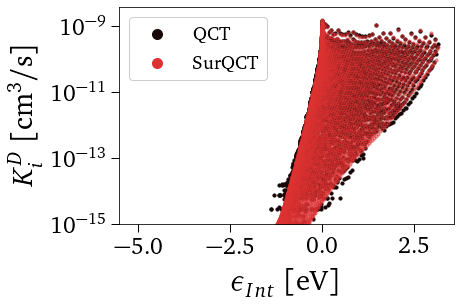

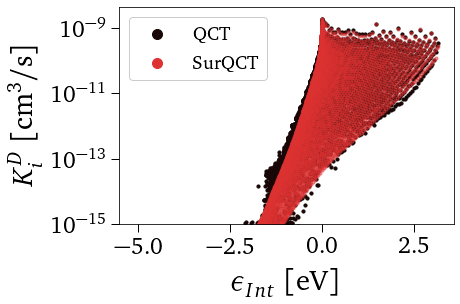

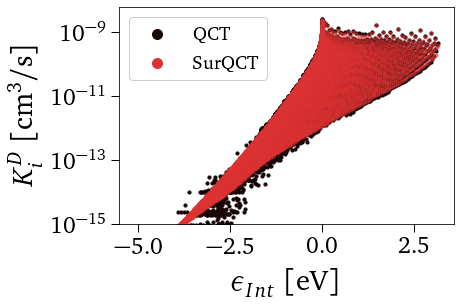

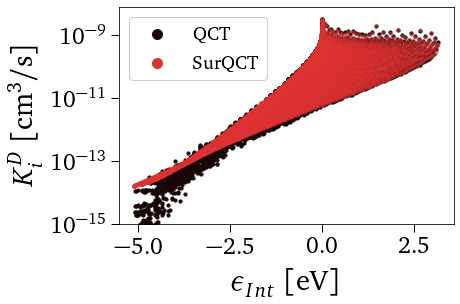

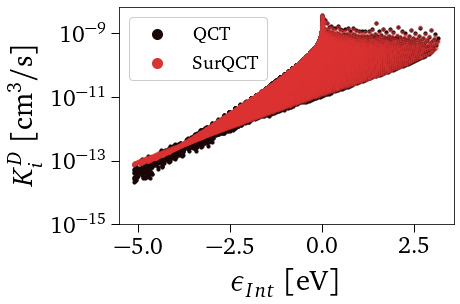

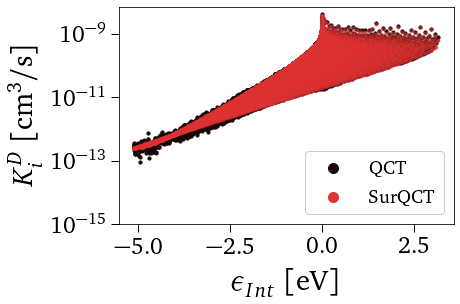

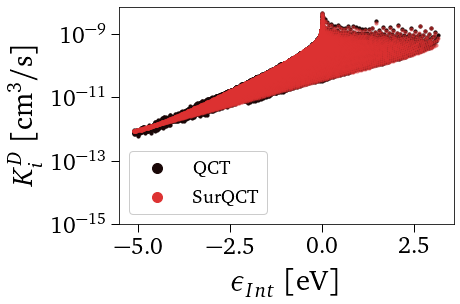

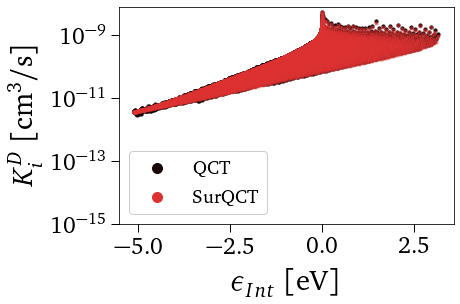

In [17]:
for i, TTran in enumerate(tqdm(TTranVec)):
    TTranStr = str(int(TTran))
    NLevels  = list(Systems.values())[0].Processes.CompInOut[InputData.RatesType]['In'][0].NLevels
    X = np.arange(NLevels)
    # True data
    if TTranStr in Systems['QCT'].Processes.Rates[InputData.RatesType].keys():
        Y = Systems['QCT'].Processes.Rates[InputData.RatesType][TTranStr]
        TrueData = (X, Y)
    else:
        TrueData = None
    # Pred data
    Y = Systems['SurQCT'].Processes.Rates[InputData.RatesType][TTranStr]
    PredData = (X, Y)
    # Plotting
    plot_prediction2D(
        System=Systems['QCT'],
        InputData=InputData,
        Path=out,
        PredData=PredData,
        TrueData=TrueData,
        FigName=f'Diss2D_T{TTranStr}K',
        ylim=[YLimTemp[i], None]
    )
    # plot_prediction3D(
    #     System=Systems['QCT'],
    #     InputData=InputData,
    #     Path=out,
    #     PredData=TrueData,
    #     TrueData=None,
    #     FigName=f'Diss3D_T{TTranStr}K',
    #     XYAxis=['ECB', 'VMax']
    # )